In [1]:
# Importing the necessary Python Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


**1. THE DATASET**

**About the heart dataset:**

Age, Systolic Blood Pressure as SystolicBP, Diastolic BP as DiastolicBP, Blood Sugar as BS, Body Temperature as BodyTemp, HeartRate and RiskLevel. All these are the responsible and significant risk factors for maternal mortality, that is one of the main concern of SDG of UN.

**Variables:**

Age: Any ages in years when a women during pregnant.

SystolicBP: Upper value of Blood Pressure in mmHg, another significant attribute during pregnancy.

DiastolicBP: Lower value of Blood Pressure in mmHg, another significant attribute during pregnancy.

BS: Blood glucose levels is in terms of a molar concentration, mmol/L.

HeartRate: A normal resting heart rate in beats per minute.

Risk Level: Predicted Risk Intensity Level during pregnancy considering the previous attribute.




*1.1 Importing and exploring the data*

In [2]:
# Importing the heart data from the CSV file
maternal = pd.read_csv('Maternal Health Risk Dataset.csv')
maternal.head()   # List the first 5 rows of tabular data


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk


In [3]:
# Identifying the descriptive statstiscs
maternal.describe()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate
count,678.000000,678.000000,678.000000,678.000000,678.000000,678.000000
mean,30.619469,113.219764,77.564897,9.186991,98.581711,74.364307
std,13.856717,19.892631,14.815390,3.606089,1.332612,8.673208
min,10.000000,70.000000,49.000000,6.000000,98.000000,7.000000
25%,19.000000,95.000000,65.000000,7.000000,98.000000,70.000000
50%,27.000000,120.000000,80.000000,7.500000,98.000000,76.000000
75%,40.000000,120.000000,90.000000,11.000000,98.000000,80.000000
max,70.000000,160.000000,100.000000,19.000000,103.000000,90.000000


In [4]:
maternal.shape

(678, 7)

In [5]:
maternal.columns

Index(['Age', 'SystolicBP', 'DiastolicBP', 'BS', 'BodyTemp', 'HeartRate',
       'RiskLevel'],
      dtype='object')

*1.2 Working on the dataset*

In [7]:
# This set of codes tells us how many data points we have for each outcome, that is, how many of observations we have
#  for high risk and low risk.
print("Number of observations for the 'Risk' outcome: ", (maternal["RiskLevel"] == "low risk").sum())
print("Number of observations for the 'No Risk' outcome: ", (maternal["RiskLevel"] == "high risk").sum())
# Here the data is imbalanced because there is far more "No Risk" (3596) than there is "risk" (644).

Number of observations for the 'Risk' outcome:  406
Number of observations for the 'No Risk' outcome:  272


In [8]:
#Let's create the numeric version of our response variable using 'map'
maternal['RiskLevel1'] = maternal.RiskLevel.map({"high risk":1, "low risk":0})

# This is synonymous to:
# maternal['RiskLevel1'] = np.where(maternal['RiskLevel'] == 'high risk', 1, 0)

In [9]:
maternal.columns

Index(['Age', 'SystolicBP', 'DiastolicBP', 'BS', 'BodyTemp', 'HeartRate',
       'RiskLevel', 'RiskLevel1'],
      dtype='object')

**At this point, I will want us to use two different libraries to run the analysis: statmodel which we are already used to; and scikit learn (sklearn), which is a very popular library for machine learning.**

# **Using Statmodel**

*1.3 Training & Testing Split Strategy*

In [10]:
# This is setting up what are our independent variables and dependent variable of the ML model
x = maternal  # Explanatory variables
y = maternal['RiskLevel1']  # Response variable

**Nemo iudex in causa sua**

Latin for “no one should be a judge in their own cause”. It is one of the cardinal rules of natural justice that no one should act as a judge a case in which they have a personal (vested) interest.

In [11]:
# FOR NOW, LET'S BORROW THE 'train_terst_split' FUNCTION FROM SKLEARN

from sklearn.model_selection import train_test_split

# Spliting the data into training data and testing data
# The training dataset is used to build the logistic model, while the testing dataset is used to evaluate the model.

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    train_size = 0.8, # This is the proportion of the dataset to include in the train split.
    random_state = 16, # This is set to control the shuffling applied to the data before spliting it. It helps to make the work reproducible
)


In [45]:
# Why do we need to set a random_state for replicability
np.random.seed(3)
np.random.rand()

0.5507979025745755

In [42]:
# Why do we need to set a random_state for replicability
np.random.randint(1, 101, size=10)

array([52, 91, 70, 98, 30, 25, 63,  8, 44, 34])

In [47]:
# Looking at the sizes of the training and testing data samples
print("Size of Training Samples: ", len(y_train))
print("Size of Testing Samples: ", len(y_test))

Size of Training Samples:  542
Size of Testing Samples:  136


In [48]:
# Within both testing and training data, let us look at how many are there for high risk or low risk outcomes.

# Testing data
print("Number of observations for the 'Low Risk' outcome in test data: ", (y_test == 0).sum())
print("Number of observations for the 'High Risk' outcome in test data: ", (y_test == 1).sum())

# Training Data.
print("Number of observations for the 'Low Risk' outcome in train data: ", (y_train == 0).sum())
print("Number of observations for the 'High Risk' outcome in train data: ", (y_train == 1).sum())

Number of observations for the 'Low Risk' outcome in test data:  84
Number of observations for the 'High Risk' outcome in test data:  52
Number of observations for the 'Low Risk' outcome in train data:  322
Number of observations for the 'High Risk' outcome in train data:  220


**2. RUNNING THE REGRESSION**

In [49]:
from statsmodels.formula.api import logit

var_struct = "RiskLevel1 ~ BS + HeartRate"

# Here, we look at a multivariate logistic regression
mat_model =logit(var_struct, data = x_train).fit()
print(mat_model.summary())

Optimization terminated successfully.
         Current function value: 0.353610
         Iterations 9
                           Logit Regression Results                           
Dep. Variable:             RiskLevel1   No. Observations:                  542
Model:                          Logit   Df Residuals:                      539
Method:                           MLE   Df Model:                            2
Date:                Tue, 05 Mar 2024   Pseudo R-squ.:                  0.4764
Time:                        04:06:03   Log-Likelihood:                -191.66
converged:                       True   LL-Null:                       -366.03
Covariance Type:            nonrobust   LLR p-value:                 1.863e-76
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -12.0156      1.629     -7.376      0.000     -15.208      -8.823
BS             1.1747      0.

**3. MAKING PREDICTIONS WITH THE MODEL**

In [51]:
expl_data = x_test[["BS", "HeartRate"]] # Subsetting the column of the explanatory variables from the test data
x_test['pred'] = mat_model.predict(expl_data)
x_test.head()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel,RiskLevel1,pred
629,35,140,100,8.0,98.0,66,high risk,1,0.297398
533,19,120,80,7.0,98.0,70,low risk,0,0.126995
89,22,90,60,7.5,102.0,60,high risk,1,0.167017
201,49,120,90,6.9,98.0,77,low risk,0,0.134849
611,13,90,65,7.5,101.0,80,low risk,0,0.254640


The approximate manual way of doing this is:

In [52]:
x_test["prob"] = 1/(1+np.exp(-(-12.0156 + 1.1747*x_test["BS"] + 0.0266*x_test["HeartRate"])))
x_test.head()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel,RiskLevel1,pred,prob
629,35,140,100,8.0,98.0,66,high risk,1,0.297398,0.296838
533,19,120,80,7.0,98.0,70,low risk,0,0.126995,0.126673
89,22,90,60,7.5,102.0,60,high risk,1,0.167017,0.166679
201,49,120,90,6.9,98.0,77,low risk,0,0.134849,0.134474
611,13,90,65,7.5,101.0,80,low risk,0,0.254640,0.254008


**4. EVALUATING THE MODEL**

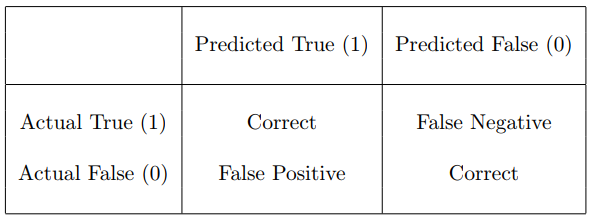

In [54]:
# prob > 0.5 means 1 (High Risk)
# prob < 0.5 means 0 (Low Risk)
x_test["prediction"]=np.where(x_test["pred"] > 0.5, 1, 0)
x_test.head()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel,RiskLevel1,pred,prob,prediction
629,35,140,100,8.0,98.0,66,high risk,1,0.297398,0.296838,0
533,19,120,80,7.0,98.0,70,low risk,0,0.126995,0.126673,0
89,22,90,60,7.5,102.0,60,high risk,1,0.167017,0.166679,0
201,49,120,90,6.9,98.0,77,low risk,0,0.134849,0.134474,0
611,13,90,65,7.5,101.0,80,low risk,0,0.254640,0.254008,0


In [55]:
# Finding accuracy by comparing the predicted to the actual.
x_test["pred2true"]= np.where(x_test["prediction"] == x_test["RiskLevel1"],'Right','Wrong')
x_test.head()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel,RiskLevel1,pred,prob,prediction,pred2true
629,35,140,100,8.0,98.0,66,high risk,1,0.297398,0.296838,0,Wrong
533,19,120,80,7.0,98.0,70,low risk,0,0.126995,0.126673,0,Right
89,22,90,60,7.5,102.0,60,high risk,1,0.167017,0.166679,0,Wrong
201,49,120,90,6.9,98.0,77,low risk,0,0.134849,0.134474,0,Right
611,13,90,65,7.5,101.0,80,low risk,0,0.254640,0.254008,0,Right


In [56]:
# ALSO, LET US BORROW THE CONFUSION MATRIX FUNCTION FROM SKLEARN
from sklearn.metrics import confusion_matrix

actual = x_test["RiskLevel1"] # The actual response
predicted = x_test["prediction"] # The predicted response

# Create a confusion matrix
cm = confusion_matrix(actual, predicted)

cm

array([[83,  1],
       [19, 33]])

In [63]:
print("True Prediction: ", len(x_test.query("pred2true == 'Right'")))
print("False Prediction: ", len(x_test.query("pred2true == 'Wrong'")))
print("Prediction Accuracy: ", len(x_test.query("pred2true == 'Right'"))/len(y_test))

True Prediction:  116
False Prediction:  20
Prediction Accuracy:  0.8529411764705882


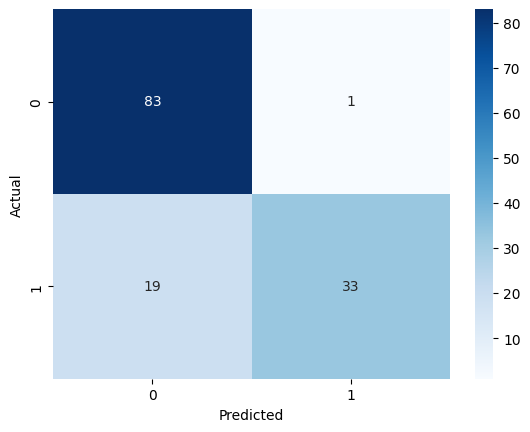

In [65]:
# Create a heatmap using seaborn and matplotlib libraries
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(cm, annot=True, cmap='Blues', cbar=True)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()